# 06 Listening to the Dome

**Series:** Physics of the Integratron (Landers, California)
**Topic T6:** what a sound actually becomes in the dome, depending on where you are, and what it sounds like.

Notebook 01 showed where reflections focus. Notebook 02 showed how long they ring. This notebook puts both together into a single description of the room for one source and one listener, called the **impulse response**. Feeding any dry sound through the impulse response gives the sound as heard in the dome, which you can play.

1. **The model.** Rays in a full 3D sphere, and three places to listen.
2. **What arrives, and when.** The echoes at each place in the first 300 ms.
3. **How long it lasts.** The decay at each place, compared with notebook 02.
4. **The impulse response.** The sound of a single click at each place, and its spectrum.
5. **Listen.** A clap, a whisper, a sung note and a singing bowl, at each place.
6. **A smooth dome versus a rough one.** What scattering does to the focus.

The audio players need a notebook front end such as VS Code or JupyterLab.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from ipywidgets import interact, Dropdown
from scipy.signal import butter, fftconvolve, sosfilt, spectrogram

SPEED_OF_SOUND = 343.0                   # m/s, air at 20 °C
DOME_RADIUS = 55 * 0.3048 / 2            # 55 ft diameter -> 8.38 m
R = DOME_RADIUS
ROOM_VOLUME = 2 / 3 * np.pi * R ** 3     # hemisphere above the floor
ROOM_SURFACE = 3 * np.pi * R ** 2        # dome + floor
ROUND_TRIP_S = 2 * R / SPEED_OF_SOUND

SAMPLE_RATE = 22050                      # Hz, enough for sound up to 11 kHz
IR_SECONDS = 10.0                        # length of each impulse response
N_RAYS = 60000
DETECTOR_RADIUS = 0.2                    # m, size of the listener in the ray model
WALL_ALPHAS = [0.05, 0.1, 0.2]           # wall absorption options

# Octave bands and air absorption in dB per km, roughly ISO 9613-1 at 20 °C, 50% humidity
BANDS_HZ = np.array([125, 250, 500, 1000, 2000, 4000, 8000])
AIR_DB_PER_KM = np.array([0.4, 1.3, 2.7, 4.7, 9.9, 30.0, 105.0])

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

## 1. The model: rays in a sphere

Notebooks 01 and 02 used a 2D slice or a sound placed exactly at the centre. Here sound can go anywhere in 3D.

- The source sends out 60,000 **rays** in random directions. Each carries an equal share of the sound energy.
- A ray travels in a straight line, reflects off the dome like a mirror, and loses the fraction $\alpha$ of its energy at every hit. As in notebook 01, the floor's mirror image turns the room into a full sphere.
- The **listener** is a small sphere 0.2 m in radius, about the size of a head. Every time a ray passes through it, the energy the ray carries is counted at the time it arrives.
- Air also absorbs sound, and much more at high frequencies. Over one second of travel (343 m) it removes about 1.6 dB at 1 kHz and 36 dB at 8 kHz. This is applied per octave band. The values are standard ones for 20 °C and 50% humidity. Dry desert air absorbs differently.

Three listening places:

| Place | Source | Listener |
|---|---|---|
| **centre: hear yourself** | at the centre | 0.25 m away, like your own ears |
| **mirror point** | on the floor 1 m from the centre | on the floor 1 m from the centre, opposite side |
| **off focus** | same source | 2.5 m to the side of the mirror point |

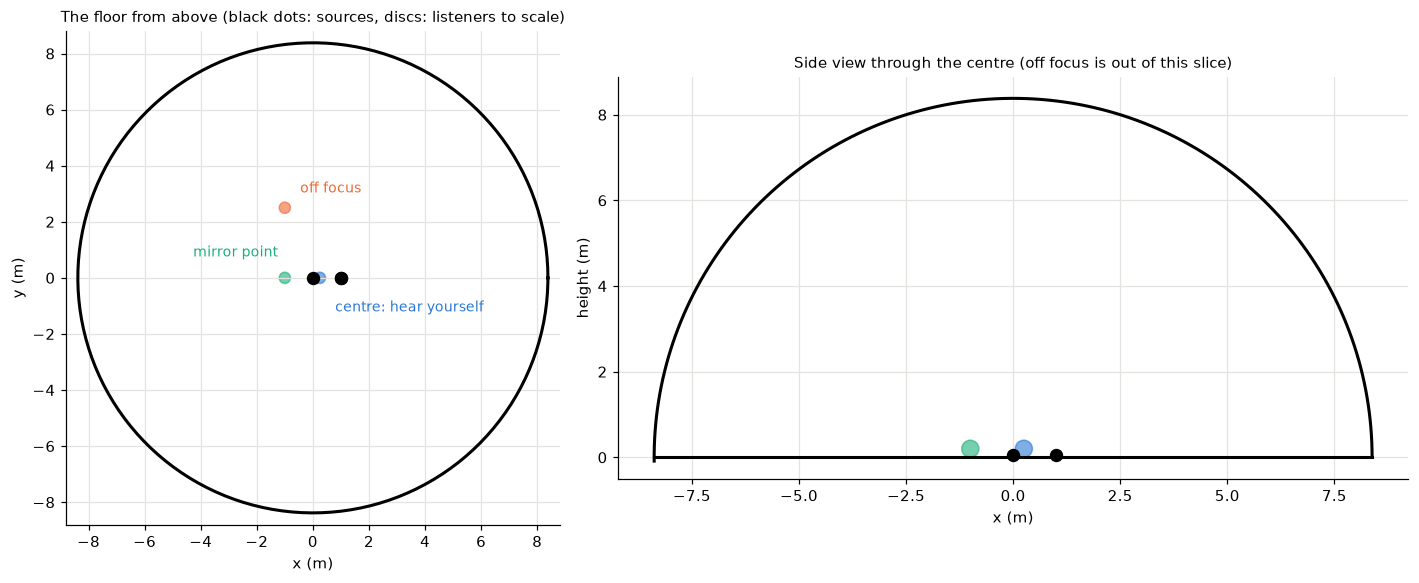

In [2]:
SCENARIOS = {
    "centre: hear yourself": {"source": (0.0, 0.0, 0.0), "listener": (0.25, 0.0, 0.0)},
    "mirror point": {"source": (1.0, 0.0, 0.0), "listener": (-1.0, 0.0, 0.0)},
    "off focus": {"source": (1.0, 0.0, 0.0), "listener": (-1.0, 2.5, 0.0)},
}
PLACE_COLOURS = {"centre: hear yourself": BLUE, "mirror point": AQUA, "off focus": ORANGE}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2),
                               gridspec_kw={"width_ratios": [1, 1.6]})
phi = np.linspace(0, 2 * np.pi, 300)
ax1.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=2)
ax2.plot(R * np.cos(phi[:151]), R * np.sin(phi[:151]), color="k", linewidth=2)
ax2.plot([-R, R], [0, 0], color="k", linewidth=2)
LABEL_OFFSETS = {"centre: hear yourself": (10, -22), "mirror point": (-60, 14),
                 "off focus": (10, 10)}
for name, place in SCENARIOS.items():
    colour = PLACE_COLOURS[name]
    sx, sy, sz = place["source"]
    lx, ly, lz = place["listener"]
    ax1.scatter(sx, sy, s=60, color="k", zorder=4)
    ax1.add_patch(plt.Circle((lx, ly), DETECTOR_RADIUS, color=colour, alpha=0.6))
    ax1.annotate(name, (lx, ly), xytext=LABEL_OFFSETS[name], textcoords="offset points",
                 color=colour, fontsize=9)
    if ly == 0:  # only listeners in the y = 0 slice appear in the side view
        ax2.scatter(sx, sz + 0.05, s=60, color="k", zorder=4)
        ax2.add_patch(plt.Circle((lx, lz + DETECTOR_RADIUS), DETECTOR_RADIUS,
                                 color=colour, alpha=0.6))
ax1.set_aspect("equal")
ax1.set_xlim(-R * 1.05, R * 1.05)
ax1.set_ylim(-R * 1.05, R * 1.05)
ax1.set_title("The floor from above (black dots: sources, discs: listeners to scale)",
              fontsize=10)
ax1.set_xlabel("x (m)")
ax1.set_ylabel("y (m)")
ax2.set_aspect("equal")
ax2.set_ylim(-0.5, R + 0.5)
ax2.set_title("Side view through the centre (off focus is out of this slice)", fontsize=10)
ax2.set_xlabel("x (m)")
ax2.set_ylabel("height (m)")
plt.tight_layout()
plt.show()

**What the figure shows**

- **Left:** the floor from above, inside the dome's 8.4 m outline. Black dots are the two sources. Coloured discs are the listeners at true size. In the centre case the source sits at the centre and the listener is just beside it. The mirror point and off focus cases share one source, 1 m right of centre.
- **Right:** the vertical slice through the centre. Everything is on the floor, where people lie. The off-focus listener is 2.5 m out of this slice, so it is not drawn.

### Tracing the rays

The function below follows every ray for 10 s of travel. Two shortcuts keep it fast:

- In a smooth sphere a ray never comes closer to the centre than where it started its current path. A ray whose path stays further from the centre than the listener can never reach the listener, so it is dropped.
- Instead of storing every pass through the listener, the energy is added straight into a time series, one per wall absorption option.

The option `scatter` sends a fraction of rays off in a random direction at each wall hit. It is used in section 6. Tracing all the rays takes about 15 s.

In [3]:
def random_directions(n, rng):
    v = rng.normal(size=(n, 3))
    return v / np.linalg.norm(v, axis=1, keepdims=True)


def trace_rays(source, listeners, scatter=0.0, seed=0, max_bounces=1500):
    # Energy reaching each listener per sample, shape (n_listeners, n_alphas, n_samples)
    rng = np.random.default_rng(seed)
    n_samples = int(IR_SECONDS * SAMPLE_RATE)
    listeners = np.asarray(listeners, float)
    energy = np.zeros((len(listeners), len(WALL_ALPHAS), n_samples))
    keep = 1 - np.array(WALL_ALPHAS)
    detector_volume = 4 / 3 * np.pi * DETECTOR_RADIUS ** 3
    reach = np.linalg.norm(listeners, axis=1).max() + DETECTOR_RADIUS

    pos = np.tile(np.asarray(source, float), (N_RAYS, 1))
    direction = random_directions(N_RAYS, rng)
    travelled = np.zeros(N_RAYS)
    hits = np.zeros(N_RAYS, int)
    alive = np.ones(N_RAYS, bool)
    for bounce in range(max_bounces):
        idx = np.flatnonzero(alive)
        if idx.size == 0:
            break
        p, u = pos[idx], direction[idx]
        b = np.sum(p * u, axis=1)
        c = np.sum(p * p, axis=1) - R ** 2
        to_wall = -b + np.sqrt(np.maximum(b * b - c, 0))

        for j, listener in enumerate(listeners):
            w = listener - p
            along = np.clip(np.sum(w * u, axis=1), 0, to_wall)
            miss = np.linalg.norm(w - along[:, None] * u, axis=1)
            inside = miss < DETECTOR_RADIUS
            if not inside.any():
                continue
            path_inside = 2 * np.sqrt(DETECTOR_RADIUS ** 2 - miss[inside] ** 2)
            arrival = (travelled[idx[inside]] + along[inside]) / SPEED_OF_SOUND
            sample = (arrival * SAMPLE_RATE).astype(int)
            ok = sample < n_samples
            weight = path_inside[ok] / (N_RAYS * detector_volume)
            for i, k in enumerate(keep):
                energy[j, i] += np.bincount(sample[ok],
                                            weights=weight * k ** hits[idx[inside]][ok],
                                            minlength=n_samples)

        # Reflect off the wall
        hit = p + to_wall[:, None] * u
        normal = hit / np.linalg.norm(hit, axis=1, keepdims=True)
        hit = normal * R * (1 - 1e-9)  # stay just inside the sphere
        u = u - 2 * np.sum(u * normal, axis=1)[:, None] * normal
        if scatter > 0:
            scattered = rng.random(idx.size) < scatter
            if scattered.any():
                # New direction from a cosine-weighted spread about the inward normal
                inward = -normal[scattered]
                tangent = random_directions(scattered.sum(), rng)
                tangent -= np.sum(tangent * inward, axis=1)[:, None] * inward
                tangent /= np.linalg.norm(tangent, axis=1, keepdims=True)
                cos_out = np.sqrt(rng.random(scattered.sum()))
                u[scattered] = (cos_out[:, None] * inward
                                + np.sqrt(1 - cos_out ** 2)[:, None] * tangent)
        pos[idx], direction[idx] = hit, u
        travelled[idx] += to_wall
        hits[idx] += 1
        alive[idx] = travelled[idx] / SPEED_OF_SOUND < IR_SECONDS
        if scatter == 0:
            # Closest approach to the centre of the new path
            closest = np.linalg.norm(np.cross(hit, u), axis=1)
            alive[idx] &= closest < reach
    return energy


ENERGY = {}
for surface, scatter in [("smooth", 0.0), ("rough", 0.1)]:
    centre = SCENARIOS["centre: hear yourself"]
    ENERGY[surface, "centre: hear yourself"] = trace_rays(
        centre["source"], [centre["listener"]], scatter)[0]
    off_centre = trace_rays(SCENARIOS["mirror point"]["source"],
                            [SCENARIOS["mirror point"]["listener"],
                             SCENARIOS["off focus"]["listener"]], scatter)
    ENERGY[surface, "mirror point"] = off_centre[0]
    ENERGY[surface, "off focus"] = off_centre[1]
print("traced", len(ENERGY), "source-listener pairs")

traced 6 source-listener pairs


## 2. What arrives, and when

The **echogram** is the energy reaching the listener over time. It is plotted in decibels relative to the strongest arrival, in 1 ms steps, for the first 300 ms. The wall absorbs α = 0.05 and the dome is smooth. Grey dashes mark multiples of the 49 ms round trip.

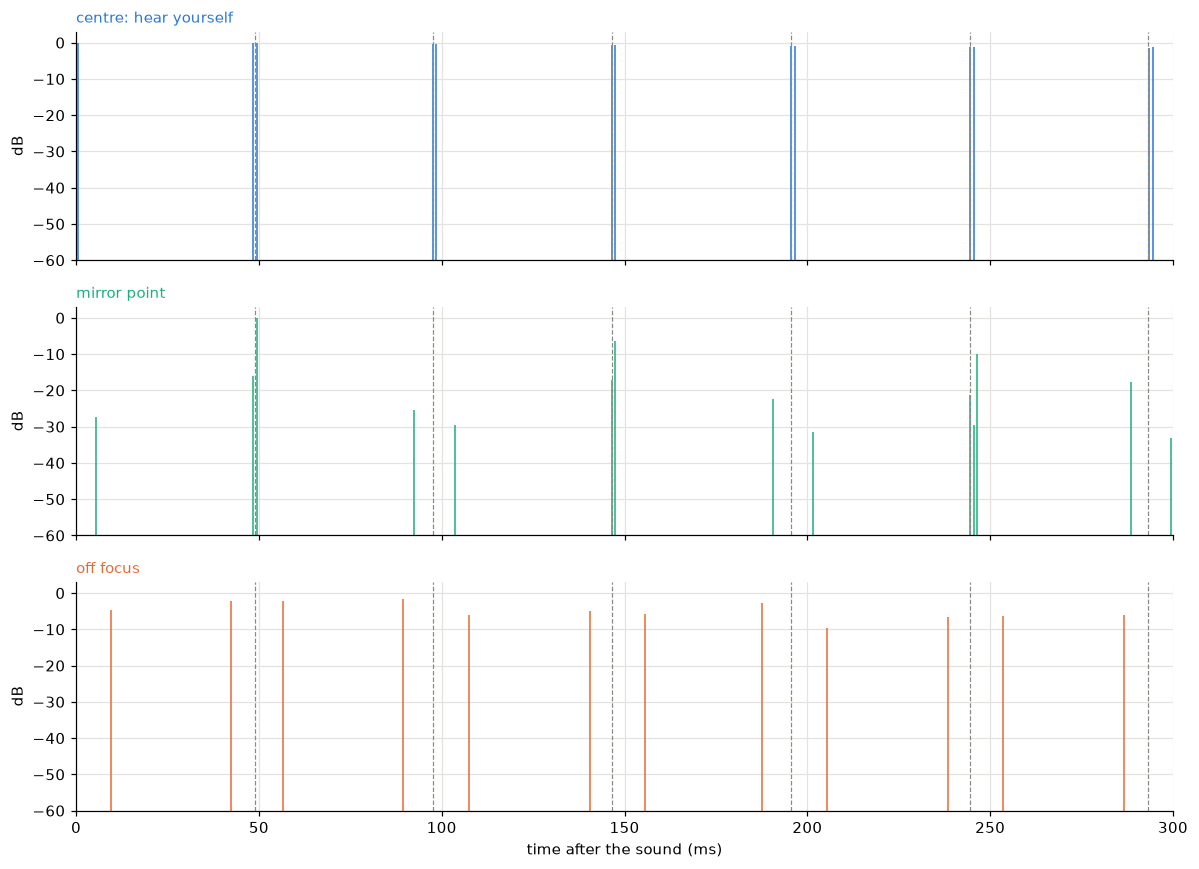

In [4]:
def echogram_db(energy, bin_ms=1.0):
    per_bin = int(SAMPLE_RATE * bin_ms / 1000)
    n_bins = len(energy) // per_bin
    binned = energy[:n_bins * per_bin].reshape(n_bins, per_bin).sum(axis=1)
    times_ms = (np.arange(n_bins) + 0.5) * bin_ms
    with np.errstate(divide="ignore"):
        return times_ms, 10 * np.log10(binned / binned.max())


fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, name in zip(axes, SCENARIOS):
    times_ms, level = echogram_db(ENERGY["smooth", name][0])
    shown = times_ms <= 300
    ax.vlines(times_ms[shown], -80, level[shown], color=PLACE_COLOURS[name], linewidth=1)
    for n in range(1, 7):
        ax.axvline(n * ROUND_TRIP_S * 1000, color=GREY, linestyle="--", linewidth=0.8)
    ax.set_ylim(-60, 3)
    ax.set_ylabel("dB")
    ax.set_title(name, fontsize=10, color=PLACE_COLOURS[name], loc="left")
axes[-1].set_xlabel("time after the sound (ms)")
axes[-1].set_xlim(0, 300)
plt.tight_layout()
plt.show()

**What the plots show** (smooth dome, α = 0.05)

- **Centre: hear yourself.** The direct sound sits on the left edge at 0.7 ms. Then come echoes as strong as the direct sound, at every multiple of 49 ms. Each echo is a pair, 48.1 and 49.6 ms on the first round. The returning sphere passes your ear 0.25 m before it reaches the centre, and again 0.25 m after it. Nothing arrives in between. You hear your own voice repeated 20 times a second, barely weaker each time.
- **Mirror point.** The direct sound arrives first, at 6 ms and 27 dB below the peak. The focused reflection arrives at 49 ms and is 27 dB stronger than the direct sound, even though it has travelled 8 times further. The sound then returns to the source and comes back, so the next strong arrivals are at 147 ms (−7 dB) and 245 ms (−10 dB), 98 ms apart. The weaker arrivals in between come from the edges of the caustic.
- **Off focus.** The direct sound arrives at 9 ms, at −5 dB. After that come many separate reflections, all within about 10 dB of the loudest, with none dominant. No focus forms here, so the sound arrives as a scattered series of echoes.

At a focus, the level a ray model gives depends on the size of the listener, here 0.2 m. Notebook 03 solves the wave version for the same source and listener. It finds the focused reflection 17 to 35 dB above the direct sound between 100 Hz and 1 kHz, which brackets the 27 dB here.

## 3. How long it lasts

The **decay curve** shows how much energy is still to come at each moment, in dB below the total. It is found by adding up the echogram backwards from the end. A straight-line fit to the part from −5 to −35 dB gives $T_{60}$, the time to fall by 60 dB.

The curves use the 1 kHz air absorption and α = 0.05. Two reference values from notebook 02 need adjusting before they can be compared:

- **Floor.** This model's floor is a perfect mirror and absorbs nothing, while notebook 02 let the floor absorb α as well. With only the dome absorbing, Sabine's formula gives 9.0 s instead of 6.0 s.
- **Air.** At 1 kHz the air takes 1.6 dB per second of travel, on top of the wall's loss. That shortens Sabine's 9.0 s to 7.2 s and the centre echo train's 13.2 s to 9.8 s.

The grey dashed line is Sabine's value for this model, including air.

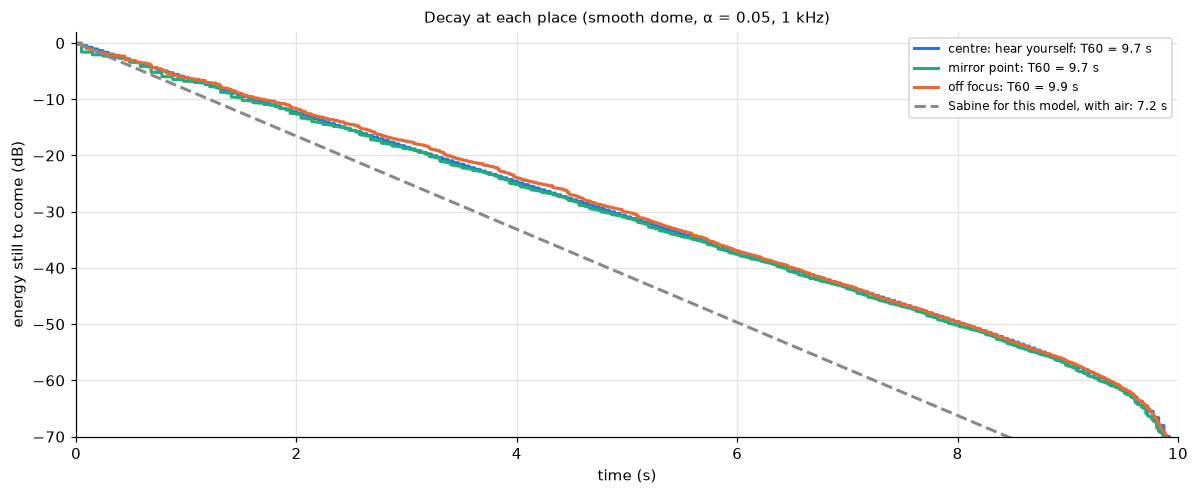

In [5]:
AIR_1K = 10 ** (-AIR_DB_PER_KM[3] / 10 * SPEED_OF_SOUND / 1000
                * np.arange(int(IR_SECONDS * SAMPLE_RATE)) / SAMPLE_RATE)


def decay_curve(energy):
    remaining = np.cumsum(energy[::-1])[::-1]
    with np.errstate(divide="ignore"):
        return 10 * np.log10(remaining / remaining[0])


def fit_t60(curve):
    t = np.arange(len(curve)) / SAMPLE_RATE
    fit = (curve <= -5) & (curve >= -35)
    if fit.sum() < 10:
        return np.nan
    slope = np.polyfit(t[fit], curve[fit], 1)[0]
    return -60 / slope


AIR_1K_DB_PER_S = AIR_DB_PER_KM[3] * SPEED_OF_SOUND / 1000
dome_area = 2 * np.pi * R ** 2  # the floor is a mirror here, so only the dome absorbs
sabine_t60 = 60 / (60 / (0.161 * ROOM_VOLUME / (WALL_ALPHAS[0] * dome_area))
                   + AIR_1K_DB_PER_S)
t = np.arange(int(IR_SECONDS * SAMPLE_RATE)) / SAMPLE_RATE
fig, ax = plt.subplots(figsize=(11, 4.6))
for name in SCENARIOS:
    curve = decay_curve(ENERGY["smooth", name][0] * AIR_1K)
    ax.plot(t, curve, color=PLACE_COLOURS[name],
            label=f"{name}: T60 = {fit_t60(curve):.1f} s")
ax.plot(t, -60 * t / sabine_t60, color=GREY, linestyle="--",
        label=f"Sabine for this model, with air: {sabine_t60:.1f} s")
ax.set_ylim(-70, 2)
ax.set_xlim(0, IR_SECONDS)
ax.set_xlabel("time (s)")
ax.set_ylabel("energy still to come (dB)")
ax.set_title("Decay at each place (smooth dome, α = 0.05, 1 kHz)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the plot shows**

- All three places decay at almost the same rate. $T_{60}$ is 9.7 s at the centre and at the mirror point, and 9.9 s off focus. That matches the 9.8 s predicted for the centre echo train with air absorption.
- The grey Sabine line gives 7.2 s. The smooth dome rings 35% longer than an evenly scattered room would.
- The three places agree because, in a perfect sphere, a ray's path never comes closer to the centre than it did when it started. Rays from a source within 1 m of the centre stay nearly radial for ever. They cross almost the full diameter each time and hit the wall only about 20 times a second, which is the slowest possible loss.
- The sharp drop at the right edge is where the 10 s simulation ends. It is not part of the room.

## 4. The impulse response

The echogram gives energy. To produce sound, it is turned into a pressure signal, the **impulse response**: what a microphone would record after a perfect click.

1. Each sample gets the square root of its energy, with a random sign. Single strong echoes stay as clicks, and a dense run of arrivals becomes noise.
2. This is done separately in seven octave bands, from 125 Hz to 8 kHz, each with its own air absorption, and the bands are added up.

The random signs lose the phase of each echo, including the 180° flip at each pass through the centre from notebook 02. The timing and energy of every arrival are kept. The comb of resonances from notebook 02 depends on that phase, so this model does not reproduce it. The 20 Hz flutter of the repeating echoes is still there.

The right-hand plot shows the decay in each octave band at the mirror point. The wall takes the same share in every band, so the bands differ only through air absorption.

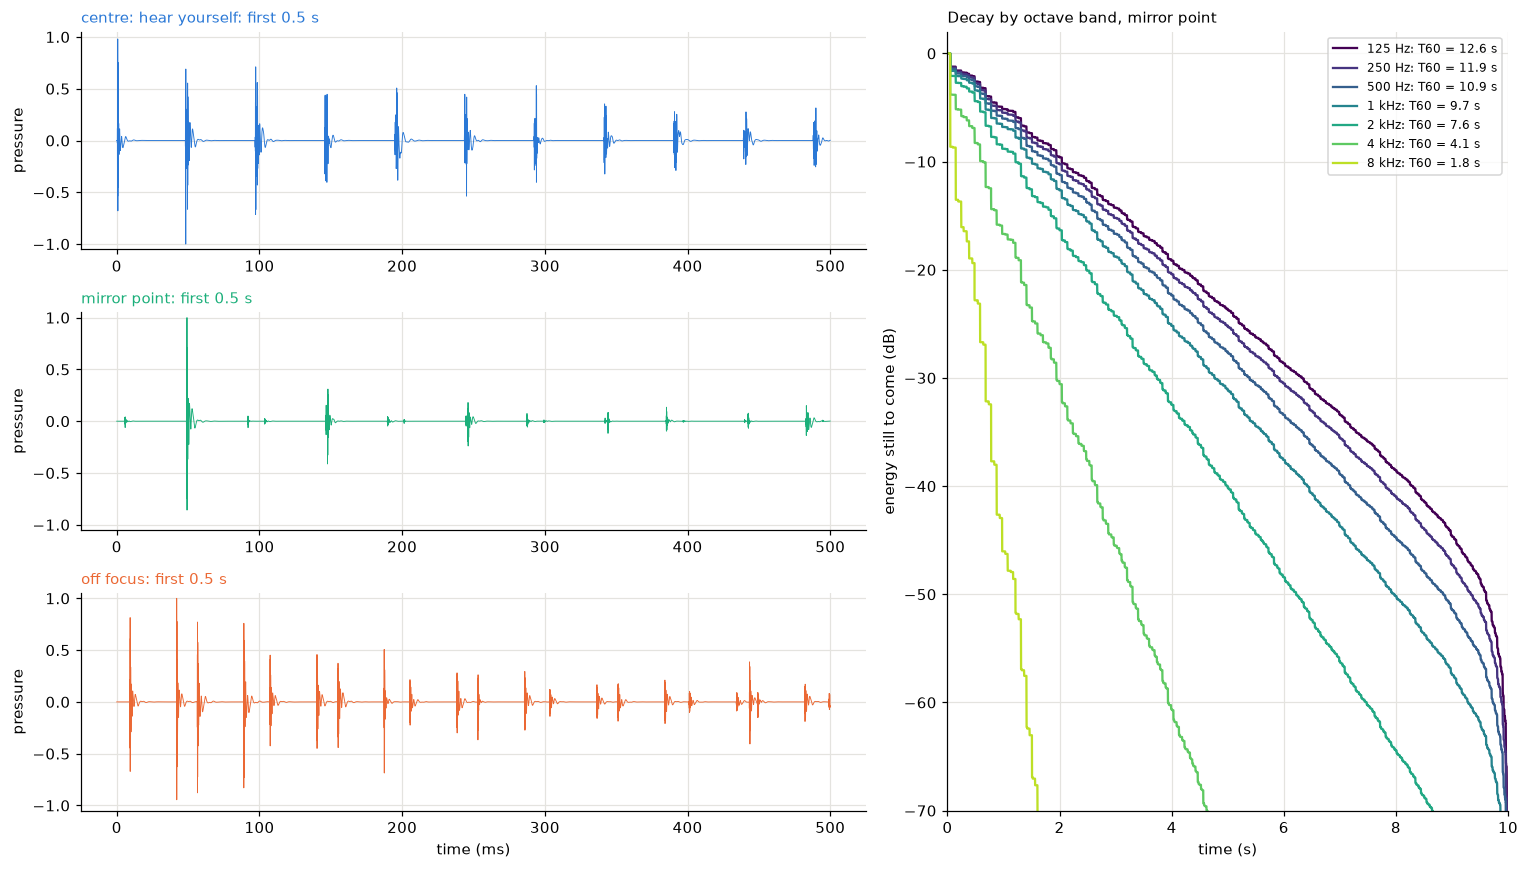

In [6]:
def band_filter(i):
    low, high = BANDS_HZ[i] / np.sqrt(2), BANDS_HZ[i] * np.sqrt(2)
    if i == 0:
        return butter(4, high, "lowpass", fs=SAMPLE_RATE, output="sos")
    if i == len(BANDS_HZ) - 1:
        return butter(4, low, "highpass", fs=SAMPLE_RATE, output="sos")
    return butter(3, [low, high], "bandpass", fs=SAMPLE_RATE, output="sos")


BAND_FILTERS = [band_filter(i) for i in range(len(BANDS_HZ))]
IR_CACHE = {}


def impulse_response(surface, place, alpha_index):
    key = (surface, place, alpha_index)
    if key not in IR_CACHE:
        energy = ENERGY[surface, place][alpha_index]
        t = np.arange(len(energy)) / SAMPLE_RATE
        signs = np.random.default_rng(1).choice([-1.0, 1.0], size=len(energy))
        ir = np.zeros(len(energy))
        for sos, air in zip(BAND_FILTERS, AIR_DB_PER_KM):
            air_loss = 10 ** (-air / 10 * SPEED_OF_SOUND * t / 1000)
            ir += sosfilt(sos, signs * np.sqrt(energy * air_loss))
        fade = int(0.5 * SAMPLE_RATE)
        ir[-fade:] *= np.linspace(1, 0, fade)
        IR_CACHE[key] = ir
    return IR_CACHE[key]


fig = plt.figure(figsize=(14, 8))
grid = fig.add_gridspec(3, 2, width_ratios=[1.4, 1])
for row, name in enumerate(SCENARIOS):
    ax1 = fig.add_subplot(grid[row, 0])
    ir = impulse_response("smooth", name, 0)
    shown = int(0.5 * SAMPLE_RATE)
    t_ms = np.arange(shown) / SAMPLE_RATE * 1000
    ax1.plot(t_ms, ir[:shown] / np.abs(ir).max(), color=PLACE_COLOURS[name],
             linewidth=0.6)
    ax1.set_ylim(-1.05, 1.05)
    ax1.set_ylabel("pressure")
    ax1.set_title(f"{name}: first 0.5 s", fontsize=10, loc="left",
                  color=PLACE_COLOURS[name])
ax1.set_xlabel("time (ms)")

ax2 = fig.add_subplot(grid[:, 1])
energy = ENERGY["smooth", "mirror point"][0]
t = np.arange(len(energy)) / SAMPLE_RATE
for band, air, colour in zip(BANDS_HZ, AIR_DB_PER_KM,
                             plt.cm.viridis(np.linspace(0, 0.9, len(BANDS_HZ)))):
    curve = decay_curve(energy * 10 ** (-air / 10 * SPEED_OF_SOUND * t / 1000))
    label = f"{band} Hz" if band < 1000 else f"{band // 1000} kHz"
    ax2.plot(t, curve, color=colour, linewidth=1.5,
             label=f"{label}: T60 = {fit_t60(curve):.1f} s")
ax2.set_ylim(-70, 2)
ax2.set_xlim(0, IR_SECONDS)
ax2.set_xlabel("time (s)")
ax2.set_ylabel("energy still to come (dB)")
ax2.set_title("Decay by octave band, mirror point", fontsize=10, loc="left")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the plots show** (smooth dome, α = 0.05)

- **Centre:** a click every 49 ms, all about the same size and shrinking slowly. This is the flutter heard when you speak at the centre.
- **Mirror point:** one dominant click at 49 ms, then strong clicks every 98 ms (147, 245, 343 ms and on) with small ones between.
- **Off focus:** a denser train of medium clicks with no dominant one.
- **Right:** the decay in each octave band at the mirror point. Low notes ring longest: 125 Hz lasts 12.6 s, 1 kHz 9.7 s, 4 kHz 4.1 s and 8 kHz only 1.8 s. The wall takes the same share in every band, so the whole spread comes from the air. A sound's high frequencies die first, and its tail grows darker as it fades.

## 5. Listen

Four dry sounds, made in code so nothing has to be downloaded:

- **clap:** a 4 ms burst of noise.
- **whisper:** three syllables of noise between 1.5 and 5 kHz.
- **voice (sung ah):** a note at 140 Hz with its harmonics shaped by the resonances of an "ah" vowel.
- **singing bowl:** a strike at 262 Hz with inharmonic overtones that ring for several seconds. Notebook 05 covers the bowl.

"In the dome" is the dry sound passed through the impulse response by **convolution**: every sample of the sound launches its own copy of the impulse response, and all the copies add up. All places use the same volume setting, so their loudness can be compared.

In [ ]:
def make_dry_sounds():
    fs = SAMPLE_RATE
    rng = np.random.default_rng(2)
    sounds = {}

    t = np.arange(int(0.05 * fs)) / fs
    sounds["clap"] = rng.normal(size=t.size) * np.exp(-t / 0.004)

    t = np.arange(int(1.3 * fs)) / fs
    noise = sosfilt(butter(4, [1500, 5000], "bandpass", fs=fs, output="sos"),
                    rng.normal(size=t.size))
    envelope = np.zeros_like(t)
    for start, stop in [(0.05, 0.3), (0.42, 0.65), (0.78, 1.15)]:
        part = (t >= start) & (t < stop)
        envelope[part] = np.sin(np.pi * (t[part] - start) / (stop - start)) ** 2
    sounds["whisper"] = noise * envelope

    t = np.arange(int(1.6 * fs)) / fs
    f0 = 140 * (1 + 0.01 * np.sin(2 * np.pi * 5 * t))
    phase = 2 * np.pi * np.cumsum(f0) / fs
    formants = [(700, 110), (1220, 120), (2600, 160)]  # vowel "ah"
    voice = np.zeros_like(t)
    for k in range(1, int(4000 / 140)):
        gain = sum(np.exp(-((k * 140 - f) / bw) ** 2) for f, bw in formants) + 0.05
        voice += gain / k * np.sin(k * phase)
    voice *= np.minimum(1, t / 0.05) * np.minimum(1, (t[-1] - t) / 0.2)
    sounds["voice (sung ah)"] = voice

    t = np.arange(int(4.0 * fs)) / fs
    bowl = np.zeros_like(t)
    for ratio, amp, decay in [(1, 1, 6.0), (2.83, 0.5, 3.0), (5.42, 0.25, 1.5),
                              (8.77, 0.12, 0.8)]:
        for split in (-0.4, 0.4):  # each overtone is a close pair, which beats
            bowl += amp * np.exp(-t / decay) * np.sin(2 * np.pi * (262 * ratio + split) * t)
    sounds["singing bowl"] = bowl

    return {name: s / np.abs(s).max() for name, s in sounds.items()}


DRY = make_dry_sounds()
WET_SECONDS = 7.0
GAIN_CACHE = {}


def in_the_dome(sound, surface, place, alpha_index):
    ir = impulse_response(surface, place, alpha_index)
    wet = fftconvolve(DRY[sound], ir)[:int((len(DRY[sound]) / SAMPLE_RATE + WET_SECONDS)
                                           * SAMPLE_RATE)]
    if sound not in GAIN_CACHE:
        # One volume setting per sound: the loudest place with the hardest wall peaks at 0.9
        GAIN_CACHE[sound] = 0.9 / max(
            np.abs(fftconvolve(DRY[sound], impulse_response("smooth", p, 0))).max()
            for p in SCENARIOS)
    return np.clip(wet * GAIN_CACHE[sound], -1, 1)


def draw_spectrogram(ax, signal, title, top_db=None):
    # top_db fixes the colour scale so that several plots can be compared
    f, t, power = spectrogram(signal, fs=SAMPLE_RATE, nperseg=1024, noverlap=768)
    level = 10 * np.log10(power + 1e-20)
    top = level.max() if top_db is None else top_db
    ax.pcolormesh(t, f, level, cmap="magma", vmin=top - 80, vmax=top, shading="auto")
    ax.set_ylim(0, 6000)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("frequency (Hz)")
    ax.set_title(title, fontsize=10)
    ax.grid(False)


@interact(
    sound=Dropdown(options=list(DRY), value="whisper", description="sound"),
    place=Dropdown(options=list(SCENARIOS), value="mirror point", description="place"),
    alpha_index=Dropdown(options=[(f"α = {a}", i) for i, a in enumerate(WALL_ALPHAS)],
                         value=0, description="wall"),
    surface=Dropdown(options=["smooth", "rough"], value="smooth", description="dome"),
)
def listen(sound, place, alpha_index, surface):
    wet = in_the_dome(sound, surface, place, alpha_index)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4),
                                   gridspec_kw={"width_ratios": [1, 2.2]})
    draw_spectrogram(ax1, np.pad(DRY[sound], (0, SAMPLE_RATE // 2)), f"{sound}: dry")
    draw_spectrogram(ax2, wet, f"{sound}: {place}, {surface} dome, "
                               f"α = {WALL_ALPHAS[alpha_index]}")
    ax1.set_xlim(0, 7)
    ax2.set_xlim(0, 7)
    plt.tight_layout()
    plt.show()
    print("Dry:")
    display(Audio(DRY[sound], rate=SAMPLE_RATE))
    print("In the dome:")
    display(Audio(wet, rate=SAMPLE_RATE, normalize=False))

interactive(children=(Dropdown(description='sound', index=1, options=('clap', 'whisper', 'voice (sung ah)', 's…

**What the plots show** (default: whisper at the mirror point, α = 0.05, smooth dome)

- **Left:** the dry whisper, three syllables of hiss between 1.5 and 5 kHz, finished after 1.15 s.
- **Right:** the same whisper in the dome. The three syllables still show as brighter vertical bands in the first second, then the sound smears into a wash that lasts past 5 s. The top of the wash fades first: above 4 kHz the sound is gone after about 4 s, while 1.5 to 3 kHz is still present at 7 s.

**Try this:**

- **Voice at the centre.** The harmonics of the sung note carry on as horizontal lines for the full 7 s, long after the 1.6 s note stops. The highest harmonics, near 3.5 to 4 kHz, fade within about 3 s. The "ah" resonances around 700 Hz and 2.6 kHz carry on.
- **Singing bowl at the centre.** The four overtones keep ringing well past the 4 s of the dry sound.
- **Clap at the mirror point.** The spectrogram is striped by the echo train. Switch the dome to rough and the stripes fade within the first second, while the tail above 3 kHz is gone by about 3 s.
- **Wall α = 0.2.** At 1 kHz the centre ring-out shortens from 9.7 s to about 2.8 s.
- **Listen at the centre with headphones.** The voice is followed by a fast buzz: the 20 echoes per second.

### Whisper at the mirror point versus off focus

The same whisper from 1 m right of centre, heard at the mirror point and 2.5 m to the side of it. Both players use the same volume setting.

mirror point: peak level -0.9 dB, average level -17.8 dB in the first 1.5 s
off focus: peak level -24.8 dB, average level -39.5 dB in the first 1.5 s


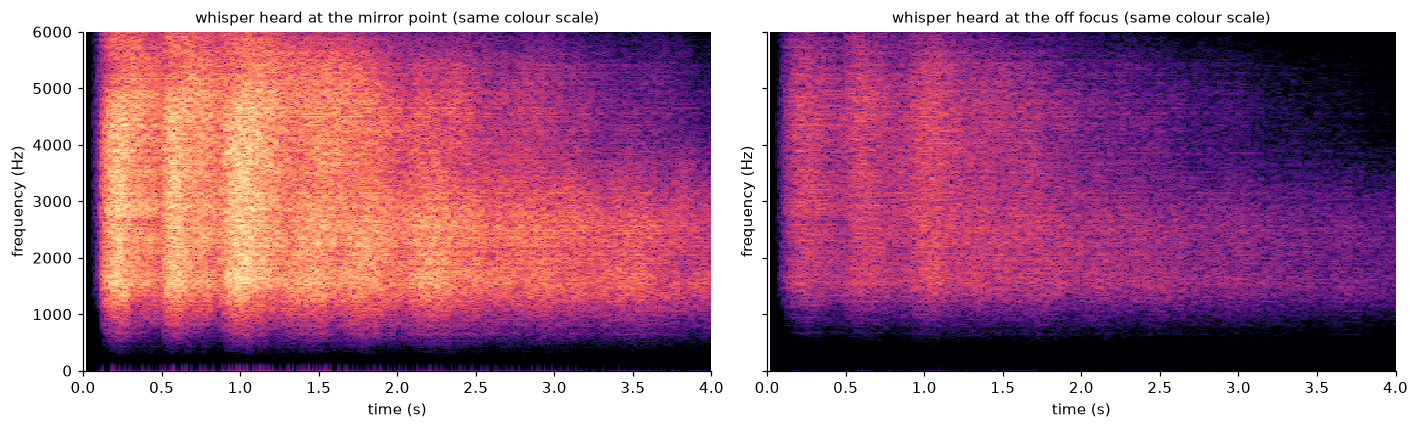

mirror point


off focus


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
top_db = 10 * np.log10(spectrogram(in_the_dome("whisper", "smooth", "mirror point", 0),
                                   fs=SAMPLE_RATE, nperseg=1024,
                                   noverlap=768)[2].max())
for ax, place in zip(axes, ["mirror point", "off focus"]):
    wet = in_the_dome("whisper", "smooth", place, 0)
    draw_spectrogram(ax, wet, f"whisper heard at the {place} (same colour scale)",
                     top_db)
    ax.set_xlim(0, 4)
    print(f"{place}: peak level {20 * np.log10(np.abs(wet).max()):.1f} dB, "
          f"average level {10 * np.log10(np.mean(wet[:int(1.5 * SAMPLE_RATE)] ** 2)):.1f} dB "
          "in the first 1.5 s")
plt.tight_layout()
plt.show()
for place in ["mirror point", "off focus"]:
    print(place)
    display(Audio(in_the_dome("whisper", "smooth", place, 0), rate=SAMPLE_RATE,
                  normalize=False))

**What the plots show**

Both plots use the same colour scale. At the mirror point the whisper is bright from 0 to 2.5 s across 1 to 6 kHz. Off focus the same whisper is darker everywhere. The printed levels put the difference at 24 dB at the peak and 22 dB averaged over the first 1.5 s. Each 10 dB sounds about twice as loud, so the whisper at the mirror point sounds more than four times as loud.

Treat the 24 dB as the size of the effect, not a precise figure. It comes from a ray model with a 0.2 m listener.

## 6. A smooth dome versus a rough one

The real dome is not a perfect mirror. Ribs, windows, doors and people send some sound off in other directions. The **rough** dome models this by sending 10% of rays in a random direction at each wall hit, spread around the inward direction. The 10% is an assumed value, not a measurement.

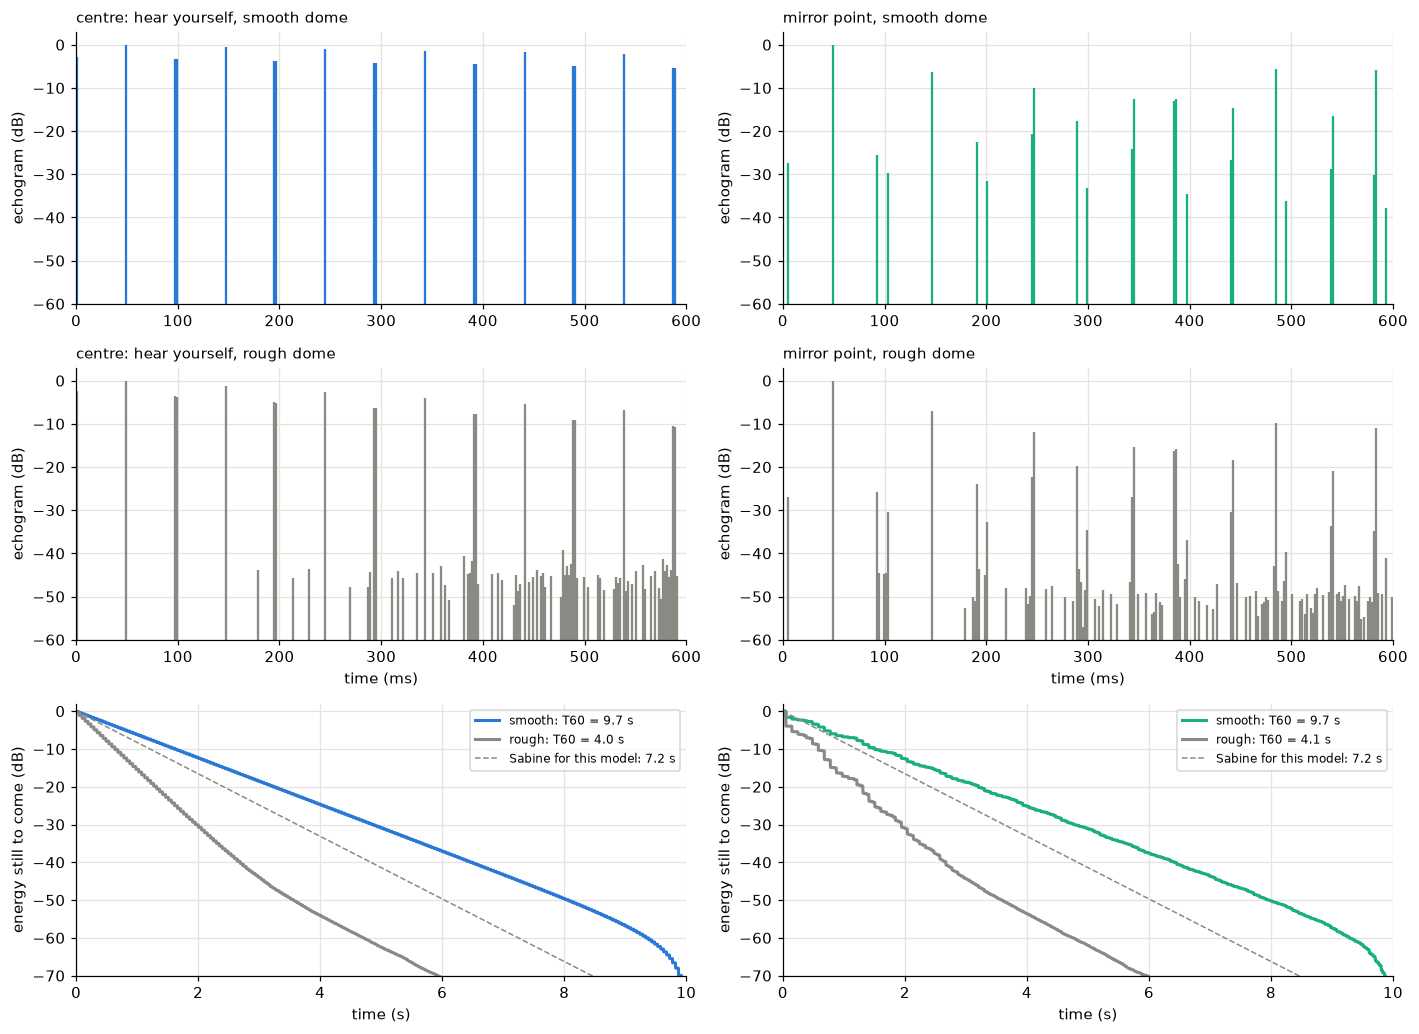

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9.5))
for col, name in enumerate(["centre: hear yourself", "mirror point"]):
    for row, (surface, colour) in enumerate([("smooth", PLACE_COLOURS[name]),
                                             ("rough", GREY)]):
        ax = axes[row, col]
        times_ms, level = echogram_db(ENERGY[surface, name][0], bin_ms=2.0)
        shown = (times_ms <= 600) & np.isfinite(level)
        ax.vlines(times_ms[shown], -80, level[shown], color=colour, linewidth=1.5)
        ax.set_ylim(-60, 3)
        ax.set_xlim(0, 600)
        ax.set_ylabel("echogram (dB)")
        ax.set_title(f"{name}, {surface} dome", fontsize=10, loc="left")
        curve = decay_curve(ENERGY[surface, name][0] * AIR_1K)
        axes[2, col].plot(t, curve, color=colour,
                          label=f"{surface}: T60 = {fit_t60(curve):.1f} s")
    axes[1, col].set_xlabel("time (ms)")
    axes[2, col].plot(t, -60 * t / sabine_t60, color=GREY, linestyle="--", linewidth=1,
                      label=f"Sabine for this model: {sabine_t60:.1f} s")
    axes[2, col].set_ylim(-70, 2)
    axes[2, col].set_xlim(0, IR_SECONDS)
    axes[2, col].set_xlabel("time (s)")
    axes[2, col].set_ylabel("energy still to come (dB)")
    axes[2, col].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the plots show** (α = 0.05)

- **Top row, smooth dome:** the clean echo patterns from section 2, out to 600 ms.
- **Middle row, rough dome:** the strong echoes still arrive at the same times, but each round trip loses an extra 10% to scattering. From about 180 ms a carpet of weak arrivals builds up between them at −40 to −55 dB. That carpet is scattered sound coming from every direction.
- **Bottom row:** the rough dome's $T_{60}$ falls from 9.7 s to 4.0 s at the centre and 4.1 s at the mirror point. The fitted part of the curve is dominated by the focused echoes, which now lose energy to the wall, the air and scattering. After about 3 s the rough curves bend to a slope close to Sabine's dashed line. By then most of what is left is the evenly scattered sound that Sabine's formula describes.

The real dome sits somewhere between these two cases. How much its ribs, windows and visitors scatter sound would take a measurement to find out.

## Summary

| | Centre: hear yourself | Mirror point | Off focus |
|---|---|---|---|
| First strong arrival | 48 ms, as loud as the direct sound | 49 ms, 27 dB above the direct sound | none dominant |
| Strong arrivals repeat every | 49 ms | 98 ms | no pattern |
| $T_{60}$ at 1 kHz, smooth dome | 9.7 s | 9.7 s | 9.9 s |
| $T_{60}$ at 1 kHz, rough dome | 4.0 s | 4.1 s | |

1. An impulse response describes a room for one source and one listener. Convolving a dry sound with it gives the sound as heard at that spot.
2. At the centre you hear yourself repeated every 49 ms at nearly full strength.
3. At the mirror point, a whisper from 2 m away arrives 27 dB stronger after one reflection than directly, and stays about 22 dB louder than at a spot 2.5 m off focus.
4. A smooth sphere keeps sound on nearly radial paths, so it rings longer than Sabine's formula predicts: 9.7 s against 7.2 s here.
5. Air absorption makes high frequencies die first. 8 kHz lasts 1.8 s and 125 Hz lasts 12.6 s.
6. Scattering from a rough surface weakens the focus and moves the ringing toward Sabine's value.

Assumed values: wall α = 0.05, air absorption for 20 °C and 50% humidity, 10% scattering for the rough dome, and a floor that reflects perfectly. People are not modelled.

**Back to:** [00 Overview](00_overview.md)